### 1. Multiband catalogue consistency

Load the optical and VIRCAM unforced measurement catalogues from the completed DP2 Fusion run.

Verify source counts, source IDs and ordering across all available bands before evaluating photometric quality.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from lsst.daf.butler import Butler

BASE_DIR = Path("/local/scratch/es3e23/projects/lsst-ir-fusion")
REPO = BASE_DIR / "dmu4/dmu4_DP2/dmu4_DP2_Example/data"
DIAG_DIR = BASE_DIR / "dmu5/dmu5_DP2/diagnostics"

RESULT_DIR = DIAG_DIR / "data/results"
FIG_DIR = DIAG_DIR / "data/figures"

RESULT_DIR.mkdir(parents=True, exist_ok=True)
FIG_DIR.mkdir(parents=True, exist_ok=True)

COLLECTION = "fusionStep3cDP2Full"
SKYMAP = "lsst_cells_v2_dp2"
TRACT = 2877
PATCH = 77

butler = Butler.from_config(str(REPO), collections=[COLLECTION])

# Discover available bands from the completed Step3c collection
refs = list(butler.registry.queryDatasets(
    "object_unforced_measurement",
    collections=[COLLECTION],
    where=f"tract={TRACT} AND patch={PATCH} AND skymap='{SKYMAP}'"
))

bands = sorted({ref.dataId["band"] for ref in refs})

cats = {}
for band in bands:
    cats[band] = butler.get(
        "object_unforced_measurement",
        dataId={
            "skymap": SKYMAP,
            "tract": TRACT,
            "patch": PATCH,
            "band": band,
        },
    )

reference_band = "i"
reference_ids = np.asarray(cats[reference_band]["id"])

rows = []
for band, cat in cats.items():
    ids = np.asarray(cat["id"])
    rows.append({
        "Band": band,
        "Sources": len(cat),
        "Same IDs/order": np.array_equal(ids, reference_ids),
    })

consistency = pd.DataFrame(rows)

display(consistency)
print("All bands consistent:", consistency["Same IDs/order"].all())

,Band,Sources,Same IDs/order
0,H,13266,True
1,J,13266,True
2,K,13266,True
3,Y,13266,True
4,Z,13266,True
5,g,13266,True
6,i,13266,True
7,r,13266,True
8,u,13266,True
9,y,13266,True


All bands consistent: True


### 2. PSF photometry quality

- Evaluate PSF fluxes, uncertainties, measurement flags, and signal-to-noise ratios for all 11 bands.
- A valid PSF measurement requires finite, positive flux and uncertainty, and an unflagged PSF fit.
- Report the fraction of valid measurements and the fraction with S/N ≥ 5.

In [2]:
quality_rows = []

for band in bands:
    cat = cats[band]

    flux = np.asarray(cat["base_PsfFlux_instFlux"], dtype=float)
    err = np.asarray(cat["base_PsfFlux_instFluxErr"], dtype=float)
    flag = np.asarray(cat["base_PsfFlux_flag"], dtype=bool)

    valid = (
        np.isfinite(flux)
        & np.isfinite(err)
        & (flux > 0)
        & (err > 0)
        & ~flag
    )

    snr = np.full(len(cat), np.nan)
    snr[valid] = flux[valid] / err[valid]

    quality_rows.append({
        "Band": band,
        "Sources": len(cat),
        "Valid PSF": int(valid.sum()),
        "Valid (%)": 100 * valid.mean(),
        "S/N >= 5": int(np.sum(snr >= 5)),
        "S/N >= 5 (%)": 100 * np.mean(snr >= 5),
        "Median S/N": np.nanmedian(snr),
    })

quality = pd.DataFrame(quality_rows)

display(
    quality.style.format({
        "Valid (%)": "{:.1f}",
        "S/N >= 5 (%)": "{:.1f}",
        "Median S/N": "{:.1f}",
    })
)

output = RESULT_DIR / f"DP2_multiband_quality_{TRACT}_{PATCH}.csv"
quality.to_csv(output, index=False)

print("Saved:", output)

,Band,Sources,Valid PSF,Valid (%),S/N >= 5,S/N >= 5 (%),Median S/N
0,H,13266,5207,39.3,2738,20.6,5.4
1,J,13266,6213,46.8,4591,34.6,9.9
2,K,13266,4920,37.1,2349,17.7,4.7
3,Y,13266,7005,52.8,6019,45.4,14.0
4,Z,13266,6585,49.6,6207,46.8,21.5
5,g,13266,7275,54.8,6596,49.7,14.3
6,i,13266,9409,70.9,8915,67.2,14.5
7,r,13266,6903,52.0,6056,45.7,13.2
8,u,13266,3020,22.8,1593,12.0,5.3
9,y,13266,3806,28.7,2125,16.0,6.0


Saved: /local/scratch/es3e23/projects/lsst-ir-fusion/dmu5/dmu5_DP2/diagnostics/data/results/DP2_multiband_quality_2877_77.csv


### PSF photometry quality — Results

All 11 bands contain finite, positive, unflagged PSF measurements for a subset of the 13,266 catalogue sources.

The valid-measurement fractions range from **22.8% (u)** to **70.9% (i)**. The fractions with S/N ≥ 5 range from **12.0% (u)** to **67.2% (i)**.

The different fractions are consistent with a multiband catalogue containing observations of different effective depths, although these diagnostics alone do not establish the expected depth or calibration accuracy.

No obvious band-wide measurement failure is apparent.

### 3. Optical–NIR colour consistency

- Examine the joint optical–near-infrared photometry using the
colours i − Y and Y − J.
- Select sources with valid PSF measurements and S/N ≥ 5
in all three bands.
- All magnitudes are calculated from the measured fluxes
using a common AB magnitude convention.
- The resulting distribution provides a basic consistency check,
not an independent absolute photometric calibration.

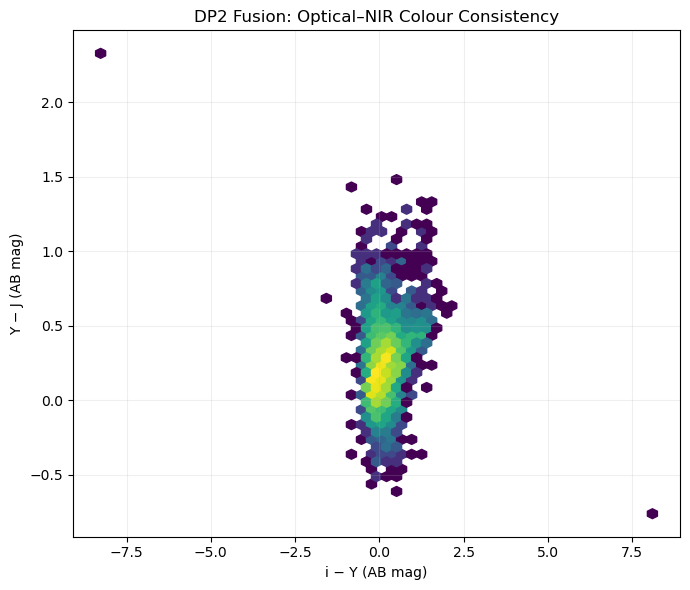

Sources with S/N >= 5 in i, Y, J: 3746
Median i − Y: 0.10264118423754098
Median Y − J: 0.23608075535908812
Saved: /local/scratch/es3e23/projects/lsst-ir-fusion/dmu5/dmu5_DP2/diagnostics/data/figures/DP2_optical_NIR_colours_2877_77.png


In [3]:
# Optical–NIR colour diagnostic

def get_good_photometry(band, min_snr=5):
    cat = cats[band]

    flux = np.asarray(cat["base_PsfFlux_instFlux"], dtype=float)
    err = np.asarray(cat["base_PsfFlux_instFluxErr"], dtype=float)
    flag = np.asarray(cat["base_PsfFlux_flag"], dtype=bool)

    good = (
        np.isfinite(flux)
        & np.isfinite(err)
        & (flux > 0)
        & (err > 0)
        & ~flag
        & (flux / np.maximum(err, 1e-30) >= min_snr)
    )

    return flux, good


fi, gi = get_good_photometry("i")
fY, gY = get_good_photometry("Y")
fJ, gJ = get_good_photometry("J")

good = gi & gY & gJ

# Fluxes are treated as nJy on a common AB scale
i_Y = -2.5 * np.log10(fi[good] / fY[good])
Y_J = -2.5 * np.log10(fY[good] / fJ[good])

fig, ax = plt.subplots(figsize=(7, 6))

ax.hexbin(
    i_Y,
    Y_J,
    gridsize=55,
    bins="log",
    mincnt=1,
    cmap="viridis"
)

ax.set_xlabel("i − Y (AB mag)")
ax.set_ylabel("Y − J (AB mag)")
ax.set_title("DP2 Fusion: Optical–NIR Colour Consistency")

ax.grid(alpha=0.2)
fig.tight_layout()

output = FIG_DIR / f"DP2_optical_NIR_colours_{TRACT}_{PATCH}.png"
fig.savefig(output, dpi=200, bbox_inches="tight")

plt.show()

print("Sources with S/N >= 5 in i, Y, J:", good.sum())
print("Median i − Y:", np.median(i_Y))
print("Median Y − J:", np.median(Y_J))
print("Saved:", output)

### 4. Forced photometry validation

Check the forced PSF photometry produced by Step3c for all 11 bands.

Verify:
- Catalogue availability and source counts.
- Source ID consistency across bands.
- Fractions of valid, unflagged PSF measurements.
- Fractions of measurements with S/N ≥ 5.

Forced photometry measures fluxes at reference source positions,
including in bands where individual sources may be too faint
for reliable unforced measurements.

In [4]:
# Forced photometry quality check for all 11 bands

forced_cats = {}
forced_rows = []

for band in bands:

    cat = butler.get(
        "object_forced_measurement",
        dataId={
            "skymap": SKYMAP,
            "tract": TRACT,
            "patch": PATCH,
            "band": band,
        },
    )

    forced_cats[band] = cat

    ids = np.asarray(cat["id"])
    same_ids = np.array_equal(ids, reference_ids)

    flux = np.asarray(cat["base_PsfFlux_instFlux"], dtype=float)
    err = np.asarray(cat["base_PsfFlux_instFluxErr"], dtype=float)
    flag = np.asarray(cat["base_PsfFlux_flag"], dtype=bool)

    valid = (
        np.isfinite(flux)
        & np.isfinite(err)
        & (flux > 0)
        & (err > 0)
        & ~flag
    )

    snr = np.full(len(cat), np.nan)
    snr[valid] = flux[valid] / err[valid]

    forced_rows.append({
        "Band": band,
        "Sources": len(cat),
        "Same IDs/order": same_ids,
        "Valid PSF": int(valid.sum()),
        "Valid (%)": 100 * valid.mean(),
        "S/N >= 5": int(np.sum(snr >= 5)),
        "S/N >= 5 (%)": 100 * np.mean(snr >= 5),
        "Median S/N": (
            np.nanmedian(snr) if valid.any() else np.nan
        ),
    })

forced_quality = pd.DataFrame(forced_rows)

# Compare forced and unforced quality
comparison = forced_quality.merge(
    quality[["Band", "Valid (%)", "S/N >= 5 (%)"]],
    on="Band",
    suffixes=(" (forced)", " (unforced)")
)

display(
    comparison.style.format({
        "Valid (%) (forced)": "{:.1f}",
        "Valid (%) (unforced)": "{:.1f}",
        "S/N >= 5 (%) (forced)": "{:.1f}",
        "S/N >= 5 (%) (unforced)": "{:.1f}",
        "Median S/N": "{:.1f}",
    })
)

output = RESULT_DIR / f"DP2_forced_quality_{TRACT}_{PATCH}.csv"
comparison.to_csv(output, index=False)

print("Saved:", output)
print("All forced catalogues contain the same IDs and order:",
      bool(forced_quality["Same IDs/order"].all()))

,Band,Sources,Same IDs/order,Valid PSF,Valid (%) (forced),S/N >= 5,S/N >= 5 (%) (forced),Median S/N,Valid (%) (unforced),S/N >= 5 (%) (unforced)
0,H,13266,True,10887,82.1,3533,26.6,2.8,39.3,20.6
1,J,13266,True,11251,84.8,6115,46.1,5.7,46.8,34.6
2,K,13266,True,10654,80.3,3083,23.2,2.3,37.1,17.7
3,Y,13266,True,11487,86.6,8194,61.8,9.2,52.8,45.4
4,Z,13266,True,11105,83.7,9349,70.5,14.2,49.6,46.8
5,g,13266,True,11611,87.5,8922,67.3,9.5,54.8,49.7
6,i,13266,True,11770,88.7,9968,75.1,12.0,70.9,67.2
7,r,13266,True,11671,88.0,8173,61.6,8.1,52.0,45.7
8,u,13266,True,10050,75.8,2385,18.0,2.4,22.8,12.0
9,y,13266,True,10404,78.4,2744,20.7,2.4,28.7,16.0


Saved: /local/scratch/es3e23/projects/lsst-ir-fusion/dmu5/dmu5_DP2/diagnostics/data/results/DP2_forced_quality_2877_77.csv
All forced catalogues contain the same IDs and order: True


### 5. K-band image and source catalogue

Display the VIRCAM K-band deep coadd and overlay source positions
from the final forced-photometry catalogue.

This provides a visual check of image quality, astrometric alignment,
and source coverage. A central image cutout is used for clarity.

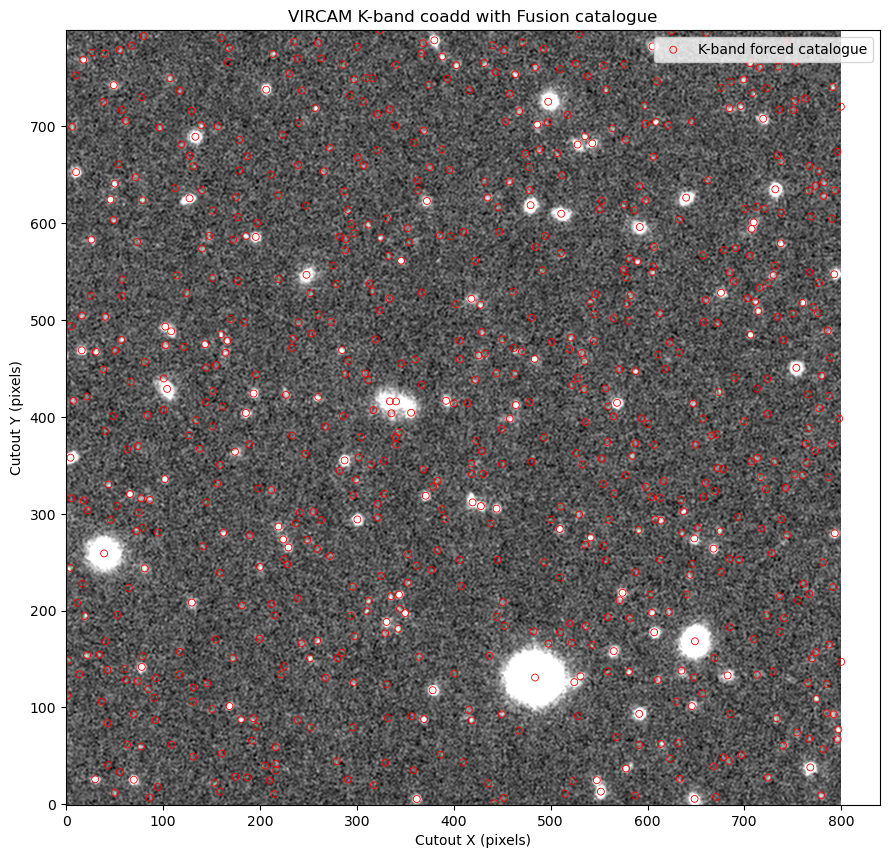

Sources within cutout: 761
Saved: /local/scratch/es3e23/projects/lsst-ir-fusion/dmu5/dmu5_DP2/diagnostics/data/figures/DP2_K_coadd_catalogue_2877_77.png
Total K-band forced catalogue sources: 13266
Sources inside 800 × 800 cutout: 761
Sources outside cutout: 12505
Fraction inside cutout: 5.74%


In [5]:
import lsst.afw.image as afwImage
from astropy.visualization import ZScaleInterval

# Load K-band deep coadd from the completed Step3b collection
k_coadd = butler.get(
    "deep_coadd",
    dataId={
        "skymap": SKYMAP,
        "tract": TRACT,
        "patch": PATCH,
        "band": "K",
    },
    collections=["videoStep3bDP2Full"],
)

# CellCoadd -> legacy Exposure for visualisation
if hasattr(k_coadd, "to_legacy_exposure"):
    exp = k_coadd.to_legacy_exposure()
elif hasattr(k_coadd, "stitch"):
    exp = k_coadd.stitch()
else:
    exp = k_coadd

image = exp.image.array
bbox = exp.getBBox()
wcs = exp.getWcs()

# Central 800 x 800 pixel cutout
size = 800
ny, nx = image.shape
x0 = (nx - size) // 2
y0 = (ny - size) // 2

cutout = image[y0:y0+size, x0:x0+size]

# Catalogue sky coordinates -> coadd pixel coordinates
from lsst.geom import SpherePoint, degrees

cat = forced_cats["K"]

xy = np.array([
    (
        lambda p: (p.getX(), p.getY())
    )(
        wcs.skyToPixel(
            SpherePoint(
                float(ra) * 180 / np.pi,
                float(dec) * 180 / np.pi,
                degrees
            )
        )
    )
    for ra, dec in zip(cat["coord_ra"], cat["coord_dec"])
])

xp = xy[:, 0] - bbox.getMinX()
yp = xy[:, 1] - bbox.getMinY()

inside = (
    (xp >= x0) & (xp < x0 + size)
    & (yp >= y0) & (yp < y0 + size)
)

vmin, vmax = ZScaleInterval().get_limits(
    cutout[np.isfinite(cutout)]
)

fig, ax = plt.subplots(figsize=(9, 9))

ax.imshow(
    cutout,
    origin="lower",
    cmap="gray",
    vmin=vmin,
    vmax=vmax,
)

ax.scatter(
    xp[inside] - x0,
    yp[inside] - y0,
    s=25,
    facecolors="none",
    edgecolors="red",
    linewidths=0.6,
    label="K-band forced catalogue",
)

ax.set_title("VIRCAM K-band coadd with Fusion catalogue")
ax.set_xlabel("Cutout X (pixels)")
ax.set_ylabel("Cutout Y (pixels)")
ax.legend(loc="upper right")

fig.tight_layout()

output = FIG_DIR / f"DP2_K_coadd_catalogue_{TRACT}_{PATCH}.png"
fig.savefig(output, dpi=200, bbox_inches="tight")

plt.show()

print("Sources within cutout:", np.count_nonzero(inside))
print("Saved:", output)
print("Total K-band forced catalogue sources:", len(cat))
print("Sources inside 800 × 800 cutout:", np.count_nonzero(inside))
print("Sources outside cutout:", np.count_nonzero(~inside))
print("Fraction inside cutout:", f"{100 * inside.mean():.2f}%")

### Multiband validation — Summary

The DP2 LSST–VISTA Fusion pipeline was tested on tract 2877, patch 77, combining six Rubin optical bands (u, g, r, i, z, y) and five VIRCAM bands (Z, Y, J, H, K).

**Pipeline and catalogue consistency**

- All 36 Step3c quanta completed successfully.
- All 11 unforced and forced measurement catalogues contain 13,266 sources.
- Source IDs and ordering are identical across all bands.

**Photometry quality**

- All bands contain valid, unflagged PSF measurements.
- For unforced photometry, the fractions with S/N ≥ 5 range from 12.0% to 67.2%.
- For forced photometry, the fractions with S/N ≥ 5 range from 18.0% to 75.1%.
- Forced photometry provides substantially more valid positive-flux measurements than unforced photometry.
- No obvious band-wide measurement failure was identified.

**Optical–NIR colour consistency**

- 3,746 sources have valid PSF measurements with S/N ≥ 5 in i, Y, and J.
- Median i − Y = +0.103 mag.
- Median Y − J = +0.236 mag.
- Most sources occupy a coherent central colour distribution, with a small number of extreme outliers.

**K-band visual inspection**

- The K-band coadd was successfully loaded and displayed.
- Forced-photometry source positions were overlaid on a central 800 × 800 pixel cutout.
- The catalogue positions show reasonable visual alignment with many detected sources.

**Conclusion**

The combined 11-band DP2 Fusion pipeline has passed the initial structural, photometric-quality, and visual consistency checks for tract 2877, patch 77.

Together with the separate six-band optical comparison against the official Rubin DP2 Object catalogue, these results support proceeding to a larger HPC pilot without further changes to the current processing configuration.

This validation does not establish exact reproduction of Rubin's intermediate detection products or independently verify the near-infrared absolute photometric calibration. Survey depth, spatial consistency, and detailed optical–NIR photometric accuracy should be evaluated during larger-scale processing.